## Overview
In this task, you will analyze a dataset containing employee information to train predictive models that determine whether employees have left the company (attrited) or not. The process will begin with an in-depth exploration of the dataset, followed by a thorough analysis of its features and the implementation of essential preprocessing techniques, such as label encoding and feature scaling. Subsequently, you will construct and assess models using K-Nearest Neighbors (KNN) and Bagging. After training and optimizing each model, you will evaluate their performance by comparing metrics such as accuracy and feature importance, in order to identify the most effective approach for accurate attrition prediction.

In [1]:
full_name = 'Arshia Goshtasbi'

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualizations
sns.set(style="whitegrid")

# Load and Explore Dataset

In [3]:
# Load the dataset
# Note: "Attrition" is our target column

df = pd.read_csv('dataset.csv')

In [4]:
df.head(5)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,29,No,Travel_Rarely,592,Research & Development,7,3,Life Sciences,1,1883,...,2,80,0,11,2,3,3,2,1,2
1,34,No,Travel_Rarely,1326,Sales,3,3,Other,1,1478,...,4,80,0,15,2,3,13,9,3,12
2,27,No,Travel_Rarely,954,Sales,9,3,Marketing,1,1965,...,1,80,0,7,5,3,7,7,0,7
3,32,No,Travel_Rarely,929,Sales,10,3,Marketing,1,722,...,4,80,0,10,2,2,10,7,0,8
4,50,No,Travel_Frequently,1234,Research & Development,20,5,Medical,1,1606,...,3,80,1,32,3,3,30,8,12,13


DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 902 entries, 0 to 901
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       902 non-null    int64
 1   Attrition                 902 non-null    str  
 2   BusinessTravel            902 non-null    str  
 3   DailyRate                 902 non-null    int64
 4   Department                902 non-null    str  
 5   DistanceFromHome          902 non-null    int64
 6   Education                 902 non-null    int64
 7   EducationField            902 non-null    str  
 8   EmployeeCount             902 non-null    int64
 9   EmployeeNumber            902 non-null    int64
 10  EnvironmentSatisfaction   902 non-null    int64
 11  Gender                    902 non-null    str  
 12  HourlyRate                902 non-null    int64
 13  JobInvolvement            902 non-null    int64
 14  JobLevel                  902 non-nul

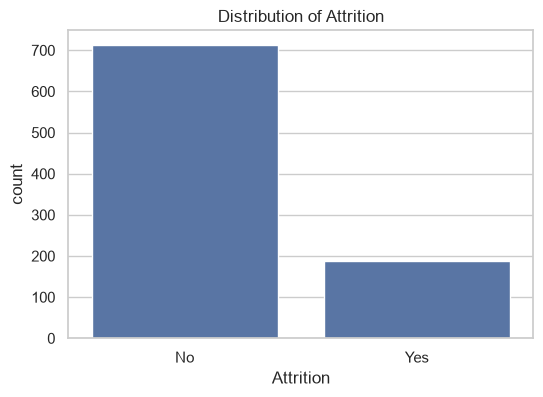

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,29,No,Travel_Rarely,592,Research & Development,7,3,Life Sciences,1,1883,...,2,80,0,11,2,3,3,2,1,2
1,34,No,Travel_Rarely,1326,Sales,3,3,Other,1,1478,...,4,80,0,15,2,3,13,9,3,12
2,27,No,Travel_Rarely,954,Sales,9,3,Marketing,1,1965,...,1,80,0,7,5,3,7,7,0,7
3,32,No,Travel_Rarely,929,Sales,10,3,Marketing,1,722,...,4,80,0,10,2,2,10,7,0,8
4,50,No,Travel_Frequently,1234,Research & Development,20,5,Medical,1,1606,...,3,80,1,32,3,3,30,8,12,13


In [5]:
# TODO: Check the basic structure of the dataset using .info() and .describe()
# Use: df.info() to check data types and missing values
# Use: df.describe() to get summary statistics of numeric features
print("DataFrame Info:")
df.info()
print("\nSummary Statistics:")
print(df.describe())
# TODO: Check for any missing values in the dataset
# Use: df.isnull().sum() to find if any column has missing values
print("\nMissing Values:")
print(df.isnull().sum())
# TODO: Explore the target variable (binary classification)
# Use value_counts() to see the distribution of our target (Attrition) column and then visualize it (bar plot).
print("\nAttrition Value Counts:")
print(df['Attrition'].value_counts())

plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Attrition')
plt.title('Distribution of Attrition')
plt.show()

df.head()

 Examine the DataFrame to gain insights into individuals' monthly income and the factors that typically influence this value.

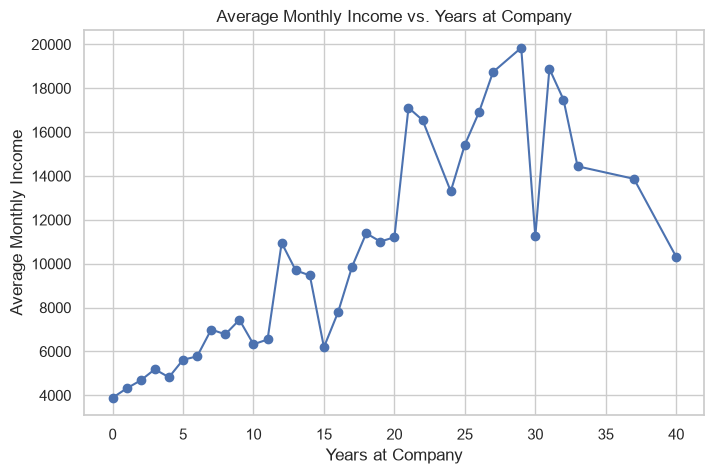


Average Monthly Income by Department:
Department
Research & Development    6073.644444
Human Resources           6564.333333
Sales                     6817.394366
Name: MonthlyIncome, dtype: float64

Department with the lowest average income: Research & Development
Department with the highest average income: Sales


In [6]:
# TODO: Plot (line plot) the average MonthlyIncome against the YearsAtCompany. 
# TODO: Then find which departments have the highest and lowest incomes on average.
plt.figure(figsize=(8,5))
income_by_year = df.groupby('YearsAtCompany')['MonthlyIncome'].mean().reset_index()
plt.plot(income_by_year['YearsAtCompany'], income_by_year['MonthlyIncome'], marker='o')
plt.xlabel('Years at Company')
plt.ylabel('Average Monthly Income')
plt.title('Average Monthly Income vs. Years at Company')
plt.grid(True)
plt.show()

income_by_dept = df.groupby('Department')['MonthlyIncome'].mean().sort_values()
print("\nAverage Monthly Income by Department:")
print(income_by_dept)
print("\nDepartment with the lowest average income:", income_by_dept.index[0])
print("Department with the highest average income:", income_by_dept.index[-1])


# Data Preprocessing

Label Encode categorical columns and create a new DataFrame. Then split this data into train and test.

In [7]:
# TODO: Label encode all categorical columns
encoded_df = df.copy()
label_encoders = {}

for col in encoded_df.select_dtypes(include='object').columns:
    le = LabelEncoder()
    encoded_df[col] = le.fit_transform(encoded_df[col])
    label_encoders[col] = le
columns_to_drop = ['EmployeeCount', 'Over18', 'StandardHours']

# Drop these columns (test.csv gets the same treatment when it is loaded below)
encoded_df.drop(columns=columns_to_drop, inplace=True, errors='ignore')

In [8]:
# Split into features and target variable
X = encoded_df.drop(columns=['Attrition'])
y = encoded_df['Attrition']

# TODO: Perform a train-test split using train_test_split() from sklearn
# Split the dataset into training and test sets with a test size of 30%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# TODO: Scale the features using StandardScaler
# Fit the scaler on the training data and transform both the training and test sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# K-Nearest Neighbors (KNN) Model

In [9]:
from collections import Counter

class CustomKNN:
    def __init__(self, k):
        """
        Initialize the KNN classifier.

        Parameters:
        - k (int): Number of neighbors to consider.
        """
        # Store the number of neighbors (k)
        self.k = k

    def fit(self, X_train, y_train):
        """
        Fit the KNN classifier to the training data.

        Parameters:
        - X_train (numpy array): Training feature vectors.
        - y_train (numpy array): Training labels.
        """
        # Store training data
        self.X_train = np.array(X_train)
        self.y_train = np.array(y_train)

    def euclidean_distance(self, x1, x2):
        """
        Calculate the Euclidean distance between two data points.

        Parameters:
        - x1 (numpy array): First data point.
        - x2 (numpy array): Second data point.

        Returns:
        - float: Euclidean distance between x1 and x2.
        """
        # TODO: Calculate and return the Euclidean distance
        return np.sqrt(np.sum((x1 - x2)**2))

    def predict(self, X_test):
        """
        Predict labels for test data.

        Parameters:
        - X_test (numpy array): Test feature vectors.

        Returns:
        - numpy array: Predicted labels.
        """
        # TODO: Predict label for each test instance and return the array of predictions
        # Compute distances from x to all training points.
        X_test = np.array(X_test)
        predictions = [self._predict(x) for x in X_test]
        return np.array(predictions)

    def _predict(self, x):
        """
        Predict label for a single data point.

        Parameters:
        - x (numpy array): Test data point.

        Returns:
        - int: Predicted label.
        """
        # TODO: Compute distances from x to all training points.
        # Find the indices and labels of k nearest neighbors.
        # Perform majority vote and return the most common label among them.
        distances = [self.euclidean_distance(x, x_train) for x_train in self.X_train]
        k_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = self.y_train[k_indices]
        vote = Counter(k_nearest_labels).most_common(1)[0][0]
        return vote


In [10]:
# You can choose any range of k values that you want.
k_values = [1, 3, 5, 7, 9, 11, 13, 15]
accuracies = []
best_accuracy = 0
best_custom_model = None
best_k = None

for k in k_values:
    y_pred_custom= []
    
    # TODO: Fit the model using the scaled training data
    # TODO: Make predictions on the scaled test data
    # TODO: Evaluate the model's accuracy for each value of k and choose the best one
    model = CustomKNN(k)
    model.fit(X_train_scaled, y_train)
    y_pred_custom = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_custom)
    accuracies.append(acc)
    print(f'k: {k} - Accuracy: {accuracy_score(y_test, y_pred_custom)}')
    
    if acc > best_accuracy:
        best_accuracy = acc
        best_custom_model = model
        best_k = k
print("\nBest k:", best_k, "with accuracy:", best_accuracy)


k: 1 - Accuracy: 0.8081180811808119


k: 3 - Accuracy: 0.8007380073800738


k: 5 - Accuracy: 0.8007380073800738


k: 7 - Accuracy: 0.8265682656826568


k: 9 - Accuracy: 0.8302583025830258


k: 11 - Accuracy: 0.8154981549815498


k: 13 - Accuracy: 0.8265682656826568


k: 15 - Accuracy: 0.8118081180811808

Best k: 9 with accuracy: 0.8302583025830258


In [11]:
# TODO: Print the accuracy and classification report using Scikit-learn metrics for your best model
from sklearn.metrics import classification_report
y_pred_best = best_custom_model.predict(X_test_scaled)
print("\nClassification Report for Best Custom KNN Model:")
print(classification_report(y_test, y_pred_best))


Classification Report for Best Custom KNN Model:
              precision    recall  f1-score   support

           0       0.83      0.99      0.90       216
           1       0.85      0.20      0.32        55

    accuracy                           0.83       271
   macro avg       0.84      0.60      0.61       271
weighted avg       0.83      0.83      0.79       271



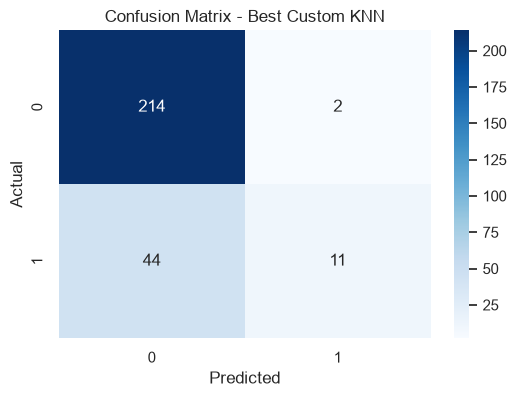

In [12]:
# TODO: Create a confusion matrix for KNN predictions
# Use confusion_matrix from sklearn.metrics
cm = confusion_matrix(y_test, y_pred_best)
# TODO: Visualize the confusion matrix using seaborn's heatmap
# Add annotations and a title for better readability
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Best Custom KNN')
plt.show()

## Evaluation
In this section, you will assess your model's performance on a new set of unseen data. Load the test.csv file (which has already been encoded), use your best_custom_model to make predictions, and save the results in a DataFrame named 'result.csv'. The DataFrame should contain a column labeled 'target', which holds your model's predictions.

In [13]:
# Load test.csv
eval_df= pd.read_csv('test.csv')
eval_df.drop(columns=columns_to_drop, inplace=True, errors='ignore')

# TODO: Use your old scaler to scale the data
for col in eval_df.select_dtypes(include='object').columns:
    if col in label_encoders:
        eval_df[col] = label_encoders[col].transform(eval_df[col])
X_eval = eval_df.copy()  # assuming test.csv does not contain target column
X_eval_scaled = scaler.transform(X_eval)
# TODO: Predict using your model
y_pred_eval = best_custom_model.predict(X_eval_scaled)


In [14]:
# Save the results as a csv file
result_df= pd.DataFrame()
result_df['target']=pd.Series(y_pred_eval)
result_df.to_csv('result.csv', index= False)

# Bagging with KNN

In [15]:
# TODO: Implement Bagging with KNN
# Use BaggingClassifier with KNeighborsClassifier as the base estimator
# Here we use the best_k value we found before

bagging_knn = BaggingClassifier(KNeighborsClassifier(n_neighbors=best_k), n_estimators=50, random_state=42)

# TODO: Fit the BaggingClassifier on the scaled training data
# Use bagging_knn.fit() with the training data
bagging_knn.fit(X_train_scaled, y_train)

# TODO: Use the trained Bagging model for predictions on the test data
# Use bagging_knn.predict()
y_pred_bagging = bagging_knn.predict(X_test_scaled)

# TODO: Print the Bagging KNN model accuracy and classification report
# Use accuracy_score and classification_report
bagging_accuracy = accuracy_score(y_test, y_pred_bagging)
print("Bagging KNN Model Accuracy: {:.4f}".format(bagging_accuracy))
print("\nClassification Report for Bagging KNN Model:")
print(classification_report(y_test, y_pred_bagging))

Bagging KNN Model Accuracy: 0.8266

Classification Report for Bagging KNN Model:
              precision    recall  f1-score   support

           0       0.82      1.00      0.90       216
           1       0.90      0.16      0.28        55

    accuracy                           0.83       271
   macro avg       0.86      0.58      0.59       271
weighted avg       0.84      0.83      0.77       271



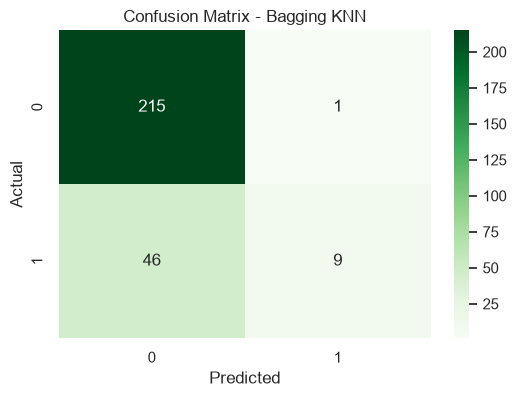

In [16]:
# TODO: Create a confusion matrix for Bagging KNN predictions
# Use confusion_matrix from sklearn.metrics
cm_bagging = confusion_matrix(y_test, y_pred_bagging)

# TODO: Visualize the confusion matrix using seaborn's heatmap
# Add annotations and a title for better readability
plt.figure(figsize=(6,4))
sns.heatmap(cm_bagging, annot=True, fmt="d", cmap="Greens")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Bagging KNN')
plt.show()

# Model Comparison

         Model  Accuracy
0   Custom KNN  0.830258
1  Bagging KNN  0.826568


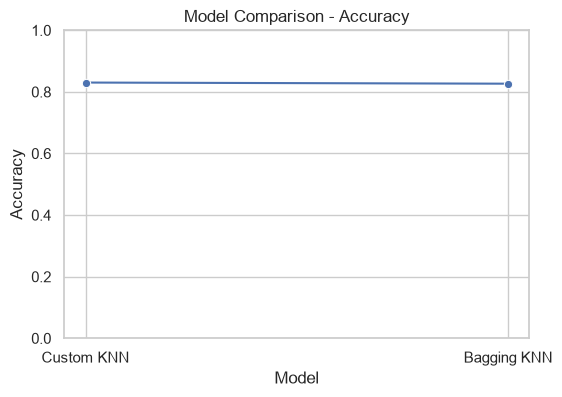

In [17]:
# TODO: Compare model accuracies for KNN, Bagging KNN
# Create a DataFrame with model names and their respective accuracies
model_comparison = pd.DataFrame({
    'Model': ['Custom KNN', 'Bagging KNN'],
    'Accuracy': [best_accuracy, bagging_accuracy]
})
print(model_comparison)
# TODO: Visualize the model comparison using a line plot
# Use seaborn's line plot to plot model names vs. accuracies
plt.figure(figsize=(6,4))
sns.lineplot(data=model_comparison, x='Model', y='Accuracy', marker='o')
plt.title('Model Comparison - Accuracy')
plt.ylim(0,1)
plt.show()